### Imports, settings & helper functions

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.colors
import plotly.graph_objects as go
from IPython.display import display

# Clean publication style
plt.style.use("default")

plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.15,
        "grid.linestyle": "-",
        "axes.titleweight": "medium",
        "axes.labelweight": "regular",
        "figure.dpi": 120,
    }
)

PRIMARY = "#1f3b73"
ACCENT = "#e36414"
TEAL = "#1b998b"


# --- Label helpers ---
def make_unique_labels(names, separator=":"):
    """Return shortest unique suffix label per name.

    Example:
    - NFCORE:...:BBMAP_BBSPLIT -> BBMAP_BBSPLIT
    - If duplicate suffix exists, expand only those duplicates to
      FASTQ_QC_TRIM_FILTER_SETSTRANDEDNESS:BBMAP_BBSPLIT, etc.
    """
    input_is_index = isinstance(names, pd.Index)
    names_series = pd.Series(names, dtype="string")

    parts = names_series.str.split(separator)
    max_depth = int(parts.str.len().max())

    labels = parts.str[-1].copy()

    for depth in range(2, max_depth + 1):
        dup_mask = labels.duplicated(keep=False)
        if not dup_mask.any():
            break

        labels.loc[dup_mask] = parts.loc[dup_mask].apply(
            lambda x: (
                separator.join(x[-depth:]) if len(x) >= depth else separator.join(x)
            )
        )

    if input_is_index:
        return pd.Index(labels)
    return labels


def truncate_left(text, max_len=45, prefix="..."):
    """Left-truncate text so the end of the label remains visible."""
    text = str(text)
    if len(text) <= max_len:
        return text
    keep = max_len - len(prefix)
    return prefix + text[-keep:]


def make_unique_display_labels(names, separator=":", max_len=45, prefix="..."):
    """Create shortest unique suffix labels, then left-truncate for display."""
    unique = make_unique_labels(names, separator=separator)
    input_is_index = isinstance(unique, pd.Index)
    unique_series = pd.Series(unique, dtype="string")
    display_labels = unique_series.apply(
        lambda s: truncate_left(s, max_len=max_len, prefix=prefix)
    )

    if input_is_index:
        return pd.Index(display_labels)
    return display_labels


# --- Data loading ---
def load_and_preprocess_trace(trace_path, verbose=True):
    """
    Load and preprocess a trace file using standardized logic.
    Returns a cleaned dataframe with only COMPLETED/CACHED tasks and valid numeric values.

    Parameters:
    -----------
    trace_path : Path or str
        Path to the trace file (tab-separated)
    verbose : bool, optional
        If True, print information about excluded tasks (default: True)

    Returns:
    --------
    pd.DataFrame
        Preprocessed dataframe with COMPLETED/CACHED tasks and cleaned numeric columns
    """
    trace_path = Path(trace_path)

    # Load tab-separated trace file
    df = pd.read_csv(trace_path, sep="\t", engine="python")
    df.columns = [str(c).strip() for c in df.columns]  # Clean column names

    initial_count = len(df)

    # --- Keep only COMPLETED/CACHED tasks (status-based inclusion) ---
    excluded_by_status = pd.DataFrame()
    if "status" in df.columns:
        status_norm = df["status"].astype(str).str.strip().str.upper()
        completed_mask = status_norm.isin(["COMPLETED", "CACHED"])
        excluded_by_status = df[~completed_mask].copy()
        df = df[completed_mask].copy()

    # --- Clean: replace "-" with NaN, then convert to numeric ---
    numeric_cols = [
        "%cpu",
        "cpus",
        "peak_rss",
        "memory",
        "realtime",
        "read_bytes",
        "write_bytes",
        "rchar",
        "wchar",
        "start",
        "complete",
        "duration",
    ]

    for col in numeric_cols:
        if col in df.columns:
            # Replace "-" and whitespace with NaN, then convert
            df[col] = (
                df[col]
                .astype(str)
                .str.replace("%", "", regex=False)
                .str.replace(",", "", regex=False)
                .str.replace("-", "nan", regex=False)
                .str.strip()
            )
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # Track excluded tasks due to NaN/invalid critical metrics
    excluded_mask = df[["%cpu", "cpus", "peak_rss", "memory", "realtime"]].isna().any(
        axis=1
    ) | (df["cpus"] <= 0)
    excluded_numeric = df[excluded_mask].copy()

    # Drop rows with missing/invalid critical values
    df = df[~excluded_mask].copy()

    # Combined excluded set for total reporting
    excluded_tasks = pd.concat([excluded_by_status, excluded_numeric], axis=0)

    if verbose:
        print(f"Total tasks in trace: {initial_count}")
        print(f"Loaded {len(df)} tasks for analysis")

        if len(excluded_by_status) > 0:
            print(f"⚠️ Excluded non-COMPLETED/CACHED tasks: {len(excluded_by_status)}")
            cols = [c for c in ["name", "status"] if c in excluded_by_status.columns]
            if cols:
                print(excluded_by_status[cols].value_counts().to_string())
            print()

        if len(excluded_numeric) > 0:
            print(
                f"⚠️ Excluded COMPLETED/CACHED tasks with missing/invalid numeric metrics: {len(excluded_numeric)}"
            )
            cols = [c for c in ["name", "status"] if c in excluded_numeric.columns]
            if cols:
                print(excluded_numeric[cols].value_counts().to_string())
            print()

        print(f"Excluded total: {len(excluded_tasks)}")

    return df


# --- Computation helpers ---
def compute_resource_contributions(df):
    """Compute total CPU, Memory, and IO time contributions for a run."""
    cpu_time = (df["realtime"] * (df["%cpu"] / 100.0)).sum()
    memory_time = (df["peak_rss"] / df["peak_rss"].max() * df["realtime"]).sum()

    if "read_bytes" in df.columns and "write_bytes" in df.columns:
        io_bytes = df["read_bytes"].fillna(0) + df["write_bytes"].fillna(0)
        io_time = (io_bytes / io_bytes.max() * df["realtime"]).sum()
    elif "rchar" in df.columns and "wchar" in df.columns:
        io_bytes = df["rchar"].fillna(0) + df["wchar"].fillna(0)
        io_time = (io_bytes / io_bytes.max() * df["realtime"]).sum()
    else:
        io_time = 0

    total_runtime = df["realtime"].sum()

    if "read_bytes" in df.columns:
        total_io_bytes = (
            df["read_bytes"].fillna(0) + df["write_bytes"].fillna(0)
        ).sum()
    else:
        total_io_bytes = (df["rchar"].fillna(0) + df["wchar"].fillna(0)).sum()

    return {
        "cpu_time": cpu_time,
        "memory_time": memory_time,
        "io_time": io_time,
        "total_runtime": total_runtime,
        "total_io_bytes": total_io_bytes,
        "task_count": len(df),
    }


def compute_per_process_contributions(df):
    """Compute CPU, Memory, and IO contributions per process."""
    work = df.copy()
    peak_rss_max = work["peak_rss"].max()

    if "read_bytes" in work.columns and "write_bytes" in work.columns:
        io_bytes = work["read_bytes"].fillna(0) + work["write_bytes"].fillna(0)
    elif "rchar" in work.columns and "wchar" in work.columns:
        io_bytes = work["rchar"].fillna(0) + work["wchar"].fillna(0)
    else:
        io_bytes = pd.Series(0, index=work.index)

    io_max = io_bytes.max()

    work["cpu_contrib"] = work["realtime"] * (work["%cpu"] / 100.0)
    work["mem_contrib"] = work["peak_rss"] / peak_rss_max * work["realtime"]
    work["io_contrib"] = (io_bytes / io_max * work["realtime"]) if io_max > 0 else 0.0

    per_process = (
        work.groupby("process")
        .agg(
            cpu_contrib=("cpu_contrib", "sum"),
            mem_contrib=("mem_contrib", "sum"),
            io_contrib=("io_contrib", "sum"),
        )
        .reset_index()
    )
    per_process["process_display"] = make_unique_display_labels(
        per_process["process"], max_len=40
    )
    return per_process

## Step 1 — Load & Preprocess Trace Files

Specify which trace files to compare and load them. Each file is preprocessed to keep only completed tasks with valid numeric values.

In [10]:
# ── Configuration ──────────────────────────────────────────────────────────────
# Specify trace files and assign a readable label to each run.
# Leave run_labels as None to use file names instead.
trace_files = [
    Path("../data/rnaseq_runs/rnaseq_test_trace_2026-03-19_16-41-59.txt"),
    Path("../data/rnaseq_runs/rnaseq_test_full_trace_2026-03-19_16-51-08.txt"),
]

run_labels = [
    "rnaseq test",
    "rnaseq test full",
]

# ── Load and preprocess all trace files ───────────────────────────────────────
print(f"Loading {len(trace_files)} trace file(s):")
results = []
per_process_all = []
loaded_dfs = {}

for trace_file in trace_files:
    print(f"  • {trace_file.name}")
    df_trace = load_and_preprocess_trace(trace_file, verbose=False)
    print(f"    → {len(df_trace)} completed tasks")

    metrics = compute_resource_contributions(df_trace)
    metrics["filename"] = trace_file.stem
    metrics["total_io_bytes_gb"] = metrics["total_io_bytes"] / (1024**3)
    results.append(metrics)

    pp = compute_per_process_contributions(df_trace)
    pp["filename"] = trace_file.stem
    per_process_all.append(pp)
    loaded_dfs[trace_file.stem] = df_trace

results_df = pd.DataFrame(results)
per_process_df = pd.concat(per_process_all, ignore_index=True)

labels = (
    run_labels
    if (run_labels and len(run_labels) == len(trace_files))
    else results_df["filename"].tolist()
)

print(f"\n✓ Ready: {len(results_df)} run(s) — {', '.join(labels)}")

Loading 2 trace file(s):
  • rnaseq_test_trace_2026-03-19_16-41-59.txt
    → 219 completed tasks
  • rnaseq_test_full_trace_2026-03-19_16-51-08.txt
    → 303 completed tasks

✓ Ready: 2 run(s) — rnaseq test, rnaseq test full


## Step 2 — Optimization Analysis

CPU and memory efficiency per process. Bubble size reflects computational burden (runtime × task count); colour reflects overall efficiency. Processes in the top-right corner are the highest-priority candidates for resource tuning.


In [11]:
from ipywidgets import Dropdown, interact


def calculate_process_metrics(df):
    work = df.copy()
    for col in ["cpus", "%cpu", "memory", "peak_rss", "realtime"]:
        work[col] = pd.to_numeric(work[col], errors="coerce")
    work = work.dropna(
        subset=["process", "cpus", "%cpu", "memory", "peak_rss", "realtime"]
    )
    work = work[
        (work["cpus"] > 0) & (work["memory"] > 0) & (work["realtime"] > 0)
    ].copy()
    if work.empty:
        return pd.DataFrame()

    work["runtime_hours"] = work["realtime"] / 3_600_000.0
    work["cpu_used_cores"] = work["%cpu"] / 100.0
    work["cpu_efficiency"] = (work["cpu_used_cores"] / work["cpus"]) * 100.0
    work["mem_requested_gb"] = work["memory"] / (1024**3)
    work["mem_used_gb"] = work["peak_rss"] / (1024**3)
    work["mem_efficiency"] = (work["mem_used_gb"] / work["mem_requested_gb"]) * 100.0
    work["cpu_hours_wasted"] = (work["cpus"] - work["cpu_used_cores"]).clip(
        lower=0
    ) * work["runtime_hours"]
    work["mem_gb_hours_wasted"] = (work["mem_requested_gb"] - work["mem_used_gb"]).clip(
        lower=0
    ) * work["runtime_hours"]

    metrics = (
        work.groupby("process")
        .agg(
            n_tasks=("process", "size"),
            avg_cpus_requested=("cpus", "mean"),
            avg_cpus_used=("cpu_used_cores", "mean"),
            avg_cpu_efficiency=("cpu_efficiency", "mean"),
            avg_mem_requested_gb=("mem_requested_gb", "mean"),
            avg_mem_used_gb=("mem_used_gb", "mean"),
            avg_mem_efficiency=("mem_efficiency", "mean"),
            avg_runtime_hours=("runtime_hours", "mean"),
            total_runtime_hours=("runtime_hours", "sum"),
            total_cpu_hours_wasted=("cpu_hours_wasted", "sum"),
            total_mem_gb_hours_wasted=("mem_gb_hours_wasted", "sum"),
        )
        .reset_index()
    )
    metrics["computational_burden"] = (
        metrics["total_runtime_hours"] * metrics["n_tasks"]
    )
    metrics["overall_efficiency"] = (
        metrics["avg_cpu_efficiency"] + metrics["avg_mem_efficiency"]
    ) / 2.0
    metrics["total_waste"] = (
        metrics["total_cpu_hours_wasted"] * 10.0 + metrics["total_mem_gb_hours_wasted"]
    )
    metrics["process_display"] = make_unique_display_labels(
        metrics["process"], max_len=40
    )
    return metrics.sort_values("total_waste", ascending=False).reset_index(drop=True)


def create_optimization_bubble_chart(
    trace_df, title="🎯 Nextflow Process Optimization Opportunities"
):
    metrics = calculate_process_metrics(trace_df)
    if metrics.empty:
        fig = go.Figure()
        fig.add_annotation(
            text="No process metrics available",
            xref="paper",
            yref="paper",
            x=0.5,
            y=0.5,
            showarrow=False,
            font=dict(size=18),
        )
        return fig

    burden_values = metrics["computational_burden"].to_numpy()
    if np.nanmax(burden_values) > np.nanmin(burden_values):
        burden_norm = (burden_values - np.nanmin(burden_values)) / (
            np.nanmax(burden_values) - np.nanmin(burden_values)
        )
        bubble_sizes = 10 + 60 * np.sqrt(burden_norm)
    else:
        bubble_sizes = np.full(len(metrics), 40)

    custom_data = np.column_stack(
        [
            metrics["process"],
            metrics["n_tasks"],
            metrics["avg_runtime_hours"],
            metrics["total_runtime_hours"],
            metrics["avg_cpus_requested"],
            metrics["avg_cpus_used"],
            metrics["avg_cpu_efficiency"],
            metrics["total_cpu_hours_wasted"],
            metrics["avg_mem_requested_gb"],
            metrics["avg_mem_used_gb"],
            metrics["avg_mem_efficiency"],
            metrics["total_mem_gb_hours_wasted"],
            metrics["overall_efficiency"],
            metrics["computational_burden"],
        ]
    )

    fig = go.Figure()
    fig.add_trace(
        go.Scatter(
            x=metrics["total_cpu_hours_wasted"],
            y=metrics["total_mem_gb_hours_wasted"],
            mode="markers",
            marker=dict(
                size=bubble_sizes,
                sizemode="diameter",
                color=metrics["overall_efficiency"].clip(lower=0, upper=100),
                colorscale="RdYlGn",
                cmin=0,
                cmax=100,
                opacity=0.85,
                line=dict(width=1.5, color="white"),
                colorbar=dict(title="Efficiency (%)", thickness=16, len=0.7, x=1.02),
            ),
            hovertext=metrics["process_display"],
            customdata=custom_data,
            hovertemplate=(
                "<b>%{hovertext}</b><br><br>"
                "Tasks: %{customdata[1]}<br>"
                "Avg Runtime: %{customdata[2]:.2f} h | Total: %{customdata[3]:.1f} h<br><br>"
                "CPU used/requested: %{customdata[5]:.1f} / %{customdata[4]:.1f} cores<br>"
                "CPU efficiency: %{customdata[6]:.1f}% | CPU-hours wasted: %{x:.2f}<br><br>"
                "Memory used/requested: %{customdata[9]:.1f} / %{customdata[8]:.1f} GB<br>"
                "Memory efficiency: %{customdata[10]:.1f}% | GB-hours wasted: %{y:.2f}<br><br>"
                "Overall efficiency: %{customdata[12]:.1f}%<extra></extra>"
            ),
            name="Processes",
        )
    )
    fig.update_layout(
        title=dict(
            text=f"{title}<br><sub>Bubble size = Runtime × Tasks | Color = Overall efficiency</sub>",
            x=0.5,
            xanchor="center",
        ),
        xaxis=dict(
            title="Total CPU-hours wasted", showgrid=True, gridcolor="lightgray"
        ),
        yaxis=dict(
            title="Total Memory GB-hours wasted", showgrid=True, gridcolor="lightgray"
        ),
        plot_bgcolor="white",
        paper_bgcolor="white",
        hovermode="closest",
        width=1200,
        height=700,
        showlegend=False,
    )
    fig.add_annotation(
        text="Top-right = highest optimization priority",
        xref="paper",
        yref="paper",
        x=0.99,
        y=0.98,
        showarrow=False,
        xanchor="right",
        yanchor="top",
        font=dict(size=11, color="darkred"),
        bgcolor="rgba(255,255,255,0.85)",
        bordercolor="darkred",
        borderwidth=1,
    )
    return fig


# ── Per-run optimization opportunity analysis ─────────────────────────────────
def plot_optimization_analysis(run_label):
    idx = labels.index(run_label)
    raw_df = loaded_dfs[results_df.iloc[idx]["filename"]]

    create_optimization_bubble_chart(
        raw_df, title=f"🎯 Process Optimization Opportunities — {run_label}"
    ).show()

    metrics = calculate_process_metrics(raw_df)
    cols = [
        "process_display",
        "n_tasks",
        "avg_cpus_requested",
        "avg_mem_requested_gb",
        "avg_cpu_efficiency",
        "avg_mem_efficiency",
        "overall_efficiency",
        "total_cpu_hours_wasted",
        "total_mem_gb_hours_wasted",
        "total_waste",
    ]
    top_n = metrics.head(10)[cols].copy()
    top_n[top_n.select_dtypes(include=[np.number]).columns] = top_n.select_dtypes(
        include=[np.number]
    ).round(2)
    print(f"\n🏆 Top optimization candidates — {run_label}\n")
    display(top_n)


interact(
    plot_optimization_analysis, run_label=Dropdown(options=labels, description="Run:")
)

interactive(children=(Dropdown(description='Run:', options=('rnaseq test', 'rnaseq test full'), value='rnaseq …

<function __main__.plot_optimization_analysis(run_label)>

## Step 3 — Process Consistency Check

Identify processes that do not appear in every run and exclude them. This ensures all comparisons are made on a consistent set of processes.


In [12]:
# ── Identify processes not present in all runs ─────────────────────────────────
all_run_files = results_df["filename"].tolist()
n_runs = len(all_run_files)
process_counts = per_process_df.groupby("process")["filename"].nunique()

consistent_processes = process_counts[process_counts == n_runs].index
missing_processes = process_counts[process_counts < n_runs].index

if len(missing_processes) > 0:
    print(f"{'='*70}")
    print(f"  EXCLUDED — processes not present in all {n_runs} run(s):")
    print(f"{'─'*70}")
    for proc in sorted(missing_processes):
        runs_with = per_process_df[per_process_df["process"] == proc][
            "filename"
        ].tolist()
        run_labels_with = [labels[all_run_files.index(f)] for f in runs_with]
        print(f"  • {proc}")
        print(f"    Found in: {', '.join(run_labels_with)}")
    print(f"{'─'*70}")
    print(
        f"  Excluded {len(missing_processes)} process(es) — "
        f"keeping {len(consistent_processes)} present in all runs."
    )
    print(f"{'='*70}")
else:
    print(f"✓ All processes are present in all {n_runs} run(s) — no exclusions.")

# Keep only processes that appear in every run
per_process_df = per_process_df[
    per_process_df["process"].isin(consistent_processes)
].copy()

print(f"\n✓ {len(consistent_processes)} processes retained for analysis.")

  EXCLUDED — processes not present in all 2 run(s):
──────────────────────────────────────────────────────────────────────
  • NFCORE_RNASEQ:PREPARE_GENOME:BBMAP_BBSPLIT
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:CUSTOM_CATADDITIONALFASTA
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:GTF2BED
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:GUNZIP_ADDITIONAL_FASTA
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:GUNZIP_GTF
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:MAKE_TRANSCRIPTS_FASTA
    Found in: rnaseq test full
  • NFCORE_RNASEQ:PREPARE_GENOME:SALMON_INDEX
    Found in: rnaseq test full
  • NFCORE_RNASEQ:PREPARE_GENOME:STAR_GENOMEGENERATE
    Found in: rnaseq test
  • NFCORE_RNASEQ:PREPARE_GENOME:UNTAR_SALMON_INDEX
    Found in: rnaseq test
  • NFCORE_RNASEQ:RNASEQ:ALIGN_STAR:STAR_ALIGN
    Found in: rnaseq test
  • NFCORE_RNASEQ:RNASEQ:ALIGN_STAR:STAR_ALIGN_IGENOMES
    Found in: rnaseq test full
  • NFCORE_RNASEQ:

## Step 4 — Analysis: Plots & Resource Tables

Plot relative resource contributions and absolute scaling trends across runs, then print which processes drove the largest increases.


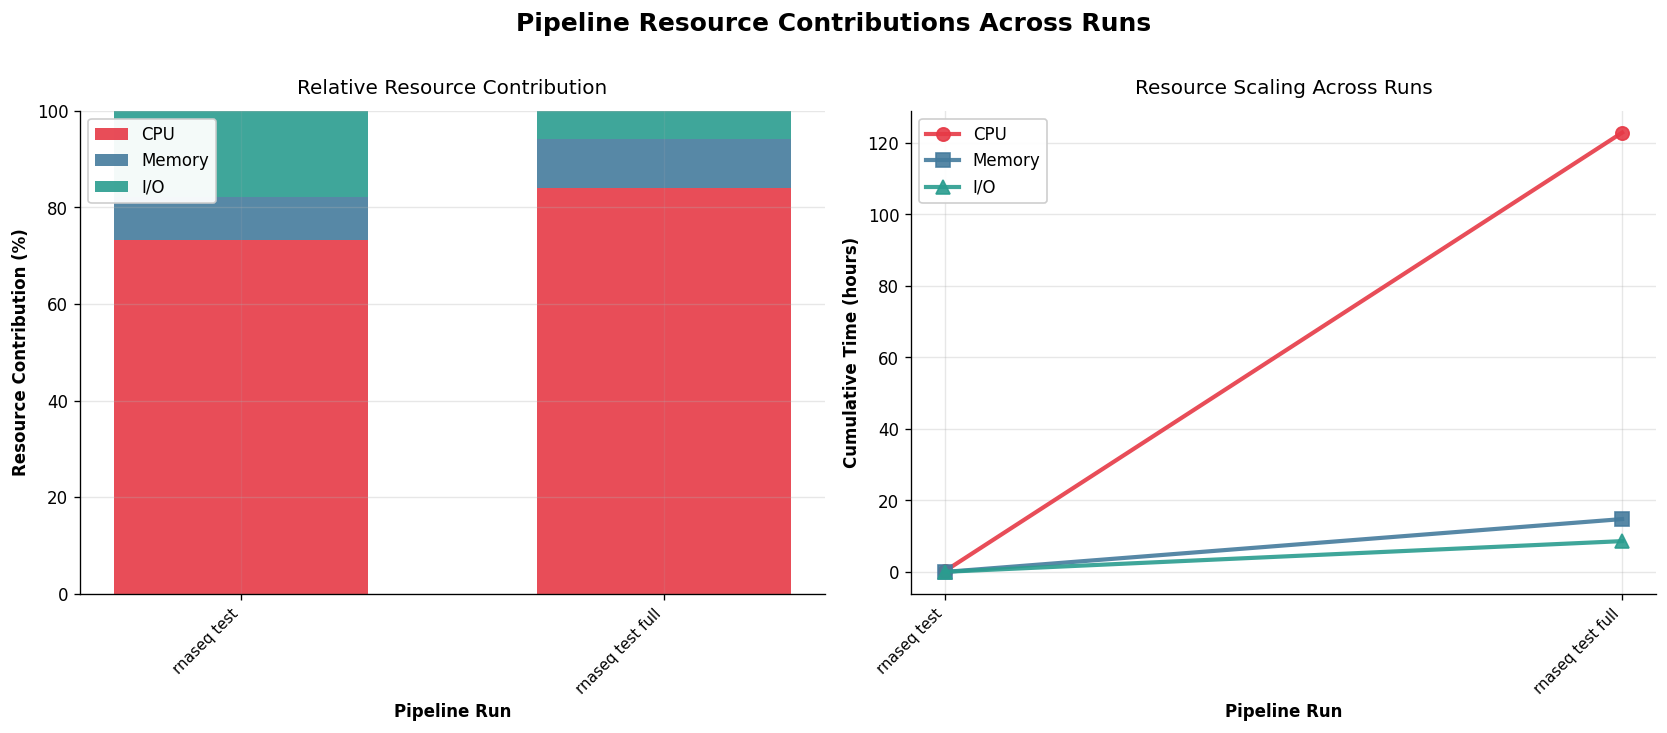


TOP PROCESSES DRIVING RESOURCE USAGE

────────────────────────────────────────────────────────────
  Top 5 processes with largest CPU increase  (rnaseq test → rnaseq test full)
────────────────────────────────────────────────────────────
                               Process  Δ CPU time (h)
                            TRIMGALORE          30.155
QUANTIFY_PSEUDO_ALIGNMENT:SALMON_QUANT          13.768
                SAMTOOLS_SORT_QUALIMAP           5.455
                 PICARD_MARKDUPLICATES           5.278
      QUANTIFY_BAM_SALMON:SALMON_QUANT           4.118

────────────────────────────────────────────────────────────
  Top 5 processes with largest Memory increase  (rnaseq test → rnaseq test full)
────────────────────────────────────────────────────────────
                               Process  Δ Memory time (h)
                 PICARD_MARKDUPLICATES              3.917
QUANTIFY_PSEUDO_ALIGNMENT:SALMON_QUANT              1.232
                 RSEQC_READDUPLICATION              1

In [13]:
cpu_color = "#E63946"
memory_color = "#457B9D"
io_color = "#2A9D8F"

x_pos = np.arange(len(results_df))
width = 0.6

total = results_df["cpu_time"] + results_df["memory_time"] + results_df["io_time"]
cpu_pct = (results_df["cpu_time"] / total * 100).values
mem_pct = (results_df["memory_time"] / total * 100).values
io_pct = (results_df["io_time"] / total * 100).values

cpu_hrs = results_df["cpu_time"].values / (1000 * 3600)
mem_hrs = results_df["memory_time"].values / (1000 * 3600)
io_hrs = results_df["io_time"].values / (1000 * 3600)

# ── Two Plots ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    "Pipeline Resource Contributions Across Runs",
    fontsize=15,
    fontweight="bold",
    y=1.01,
)

# Plot 1 – Relative contributions (stacked bar)
ax1 = axes[0]
ax1.bar(x_pos, cpu_pct, width, label="CPU", color=cpu_color, alpha=0.9)
ax1.bar(
    x_pos, mem_pct, width, bottom=cpu_pct, label="Memory", color=memory_color, alpha=0.9
)
ax1.bar(
    x_pos,
    io_pct,
    width,
    bottom=cpu_pct + mem_pct,
    label="I/O",
    color=io_color,
    alpha=0.9,
)
ax1.set_ylabel("Resource Contribution (%)", fontweight="bold")
ax1.set_xlabel("Pipeline Run", fontweight="bold")
ax1.set_title("Relative Resource Contribution", fontsize=12, pad=10)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
ax1.legend(loc="upper left", framealpha=0.95)
ax1.set_ylim(0, 100)
ax1.grid(axis="y", alpha=0.3)

# Plot 2 – Scaling trends (line plot)
ax2 = axes[1]
ax2.plot(
    x_pos,
    cpu_hrs,
    marker="o",
    linewidth=2.5,
    markersize=8,
    label="CPU",
    color=cpu_color,
    alpha=0.9,
)
ax2.plot(
    x_pos,
    mem_hrs,
    marker="s",
    linewidth=2.5,
    markersize=8,
    label="Memory",
    color=memory_color,
    alpha=0.9,
)
ax2.plot(
    x_pos,
    io_hrs,
    marker="^",
    linewidth=2.5,
    markersize=8,
    label="I/O",
    color=io_color,
    alpha=0.9,
)
ax2.set_xlabel("Pipeline Run", fontweight="bold")
ax2.set_ylabel("Cumulative Time (hours)", fontweight="bold")
ax2.set_title("Resource Scaling Across Runs", fontsize=12, pad=10)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
ax2.legend(loc="upper left", framealpha=0.95)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ── Process-level delta table ──────────────────────────────────────────────────
print("\n" + "=" * 80)
print("TOP PROCESSES DRIVING RESOURCE USAGE")
print("=" * 80)

filenames = results_df["filename"].tolist()

if len(filenames) >= 2:
    first, last = filenames[0], filenames[-1]
    label_first, label_last = labels[0], labels[-1]
    df_first = per_process_df[per_process_df["filename"] == first].set_index("process")
    df_last = per_process_df[per_process_df["filename"] == last].set_index("process")

    common = df_first.index.intersection(df_last.index)
    delta = pd.DataFrame(
        {
            "process": common,
            "cpu_delta": (
                df_last.loc[common, "cpu_contrib"] - df_first.loc[common, "cpu_contrib"]
            ).values,
            "mem_delta": (
                df_last.loc[common, "mem_contrib"] - df_first.loc[common, "mem_contrib"]
            ).values,
            "io_delta": (
                df_last.loc[common, "io_contrib"] - df_first.loc[common, "io_contrib"]
            ).values,
        }
    )
    delta["process_display"] = make_unique_display_labels(delta["process"], max_len=50)

    for col in ["cpu_delta", "mem_delta", "io_delta"]:
        delta[col] = delta[col] / (1000 * 3600)

    TOP = 5
    for metric, col in [
        ("CPU", "cpu_delta"),
        ("Memory", "mem_delta"),
        ("I/O", "io_delta"),
    ]:
        print(f"\n{'─'*60}")
        print(
            f"  Top {TOP} processes with largest {metric} increase  ({label_first} → {label_last})"
        )
        print(f"{'─'*60}")
        top = delta.nlargest(TOP, col)[["process_display", col]].copy()
        top.columns = ["Process", f"Δ {metric} time (h)"]
        top[f"Δ {metric} time (h)"] = top[f"Δ {metric} time (h)"].round(3)
        print(top.to_string(index=False))

else:
    pp = per_process_all[0].copy()
    for metric, col in [
        ("CPU", "cpu_contrib"),
        ("Memory", "mem_contrib"),
        ("I/O", "io_contrib"),
    ]:
        print(f"\nTop 5 {metric} contributors ({labels[0]}):")
        top = pp.nlargest(5, col)[["process_display", col]].copy()
        top[col] = (top[col] / (1000 * 3600)).round(3)
        top.columns = ["Process", f"{metric} time (h)"]
        print(top.to_string(index=False))

print(f"\nSummary: {len(results_df)} run(s) analyzed")
print(
    f"Runtime range: {(results_df['total_runtime'] / (1000*3600)).min():.2f} – "
    f"{(results_df['total_runtime'] / (1000*3600)).max():.2f} hours"
)
print(
    f"Avg contributions — CPU: {cpu_pct.mean():.1f}%  Memory: {mem_pct.mean():.1f}%  I/O: {io_pct.mean():.1f}%"
)

In [14]:
# ── Per-process resource composition — select one run ─────────────────────────
# Uses the full unfiltered per-process data (all processes, including those
# not present in every run).
from ipywidgets import Dropdown, interact

TOP_N = 25  # top N processes shown (sorted by total contribution)


def plot_process_composition(run_label):
    idx = labels.index(run_label)
    pp = per_process_all[idx].copy()

    pp["cpu_h"] = pp["cpu_contrib"] / (1000 * 3600)
    pp["mem_h"] = pp["mem_contrib"] / (1000 * 3600)
    pp["io_h"] = pp["io_contrib"] / (1000 * 3600)
    pp["total_h"] = pp["cpu_h"] + pp["mem_h"] + pp["io_h"]

    pp = pp.nlargest(TOP_N, "total_h").sort_values("total_h")
    pp["label"] = make_unique_display_labels(pp["process"], max_len=45)

    y = np.arange(len(pp))

    fig, ax = plt.subplots(figsize=(10, max(6, len(pp) * 0.38)))
    ax.barh(y, pp["cpu_h"].values, color=cpu_color, alpha=0.9, label="CPU")
    ax.barh(
        y,
        pp["mem_h"].values,
        left=pp["cpu_h"].values,
        color=memory_color,
        alpha=0.9,
        label="Memory",
    )
    ax.barh(
        y,
        pp["io_h"].values,
        left=(pp["cpu_h"] + pp["mem_h"]).values,
        color=io_color,
        alpha=0.9,
        label="I/O",
    )

    ax.set_yticks(y)
    ax.set_yticklabels(pp["label"].values, fontsize=8)
    ax.set_xlabel("Resource Contribution (hours)", fontweight="bold")
    ax.set_title(f"Per-Process Resource Composition — {run_label}", fontsize=13, pad=10)
    ax.legend(loc="lower right", framealpha=0.95, fontsize=9)
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


interact(
    plot_process_composition, run_label=Dropdown(options=labels, description="Run:")
)

interactive(children=(Dropdown(description='Run:', options=('rnaseq test', 'rnaseq test full'), value='rnaseq …

<function __main__.plot_process_composition(run_label)>

### Process Scaling Explorer (interactive)

Scaling curves per process for the top contributors per resource type. Use the buttons to switch between CPU, Memory, and I/O views. Click a process in the legend to show or hide it across all views.

In [15]:
TOP_PROC = 15  # top N processes shown per resource type

RESOURCE_COLORS = {
    "CPU": "#E63946",
    "Memory": "#457B9D",
    "I/O": "#2A9D8F",
    "Combined": "#6A4C93",
}

# Build long-form DataFrame: one row per (process × run)
records = []
for trace_file, run_label in zip(trace_files, labels):
    filename = trace_file.stem
    subset = per_process_df[per_process_df["filename"] == filename].copy()
    subset["run_label"] = run_label
    records.append(subset)

long_df = pd.concat(records, ignore_index=True)

for col in ["cpu_contrib", "mem_contrib", "io_contrib"]:
    long_df[col + "_h"] = long_df[col] / (1000 * 3600)

long_df["total_contrib_h"] = (
    long_df["cpu_contrib_h"] + long_df["mem_contrib_h"] + long_df["io_contrib_h"]
)

run_order = {lbl: i for i, lbl in enumerate(labels)}
long_df["run_idx"] = long_df["run_label"].map(run_order)

# Top processes per resource (by total contribution across all runs)
top_cpu = (
    long_df.groupby("process")["cpu_contrib_h"].sum().nlargest(TOP_PROC).index.tolist()
)
top_mem = (
    long_df.groupby("process")["mem_contrib_h"].sum().nlargest(TOP_PROC).index.tolist()
)
top_io = (
    long_df.groupby("process")["io_contrib_h"].sum().nlargest(TOP_PROC).index.tolist()
)
top_combined = (
    long_df.groupby("process")["total_contrib_h"]
    .sum()
    .nlargest(TOP_PROC)
    .index.tolist()
)

# Stable color per process
palette = plotly.colors.qualitative.Dark24 + plotly.colors.qualitative.Light24
all_procs = list(dict.fromkeys(top_cpu + top_mem + top_io + top_combined))
proc_color = {p: palette[i % len(palette)] for i, p in enumerate(all_procs)}

# Display name lookup
proc_display = {}
for proc in all_procs:
    row = long_df[long_df["process"] == proc]
    if not row.empty:
        proc_display[proc] = row["process_display"].iloc[0]

resource_config = [
    ("CPU", top_cpu, "cpu_contrib_h", "CPU contribution (hours)"),
    ("Memory", top_mem, "mem_contrib_h", "Memory contribution (hours)"),
    ("I/O", top_io, "io_contrib_h", "I/O contribution (hours)"),
    ("Combined", top_combined, "total_contrib_h", "Combined contribution (hours)"),
]

fig = go.Figure()
trace_ranges = {}

for resource, procs, metric, _ in resource_config:
    start = len(fig.data)
    is_first_resource = resource == "CPU"
    # Track legend entries per resource so each view has its own legend
    legend_shown_for_resource = set()

    for proc in procs:
        subset = long_df[long_df["process"] == proc].sort_values("run_idx")
        if subset.empty:
            continue
        display_name = proc_display.get(proc, proc)
        color = proc_color.get(proc, "#888888")

        show_in_legend = display_name not in legend_shown_for_resource
        if show_in_legend:
            legend_shown_for_resource.add(display_name)

        customdata = [
            [
                row.cpu_contrib_h,
                row.mem_contrib_h,
                row.io_contrib_h,
                row.total_contrib_h,
                row.run_label,
            ]
            for row in subset.itertuples()
        ]
        rc = RESOURCE_COLORS["CPU"]
        mc = RESOURCE_COLORS["Memory"]
        ic = RESOURCE_COLORS["I/O"]
        cc = RESOURCE_COLORS["Combined"]
        hovertemplate = (
            f"<b>{display_name}</b><br>"
            "<i>%{customdata[4]}</i><br>"
            "<br>"
            f"<b style='color:{rc}'>CPU</b>      %{{customdata[0]:.3f}} h<br>"
            f"<b style='color:{mc}'>Memory</b>   %{{customdata[1]:.3f}} h<br>"
            f"<b style='color:{ic}'>I/O</b>      %{{customdata[2]:.3f}} h<br>"
            f"<b style='color:{cc}'>Combined</b> %{{customdata[3]:.3f}} h"
            "<extra></extra>"
        )

        fig.add_trace(
            go.Scatter(
                x=subset["run_label"].tolist(),
                y=subset[metric].tolist(),
                mode="lines+markers",
                name=display_name,
                legendgroup=f"{resource}_{display_name}",
                showlegend=show_in_legend,
                customdata=customdata,
                hovertemplate=hovertemplate,
                marker=dict(
                    size=10,
                    color=color,
                    line=dict(width=2, color="white"),
                    symbol="circle",
                ),
                line=dict(width=2.5, color=color),
                visible=is_first_resource,
            )
        )

    trace_ranges[resource] = (start, len(fig.data))

total_traces = len(fig.data)


def vis_list(active_resource):
    result = [False] * total_traces
    s, e = trace_ranges[active_resource]
    for i in range(s, e):
        result[i] = True
    return result


buttons = [
    dict(
        label=f" {res} ",
        method="update",
        args=[
            {"visible": vis_list(res)},
            {
                "yaxis.title.text": ytitle,
                "title.text": f"Process Scaling Explorer — Top {TOP_PROC} by {res}",
            },
        ],
    )
    for res, _, _, ytitle in resource_config
]

fig.update_layout(
    title=dict(
        text=f"Process Scaling Explorer — Top {TOP_PROC} by CPU",
        font=dict(size=16, color="#1a1a2e", family="sans-serif"),
        x=0,
        xanchor="left",
        pad=dict(l=4, b=10),
    ),
    updatemenus=[
        dict(
            type="buttons",
            direction="right",
            x=0.0,
            xanchor="left",
            y=1.0,
            yanchor="bottom",
            pad=dict(r=6, t=6, b=6),
            buttons=buttons,
            showactive=True,
            bgcolor="#f2f4f8",
            bordercolor="#c8cdd6",
            borderwidth=1,
            font=dict(size=12, color="#222"),
            active=0,
        )
    ],
    xaxis=dict(
        title=dict(text="Pipeline Run", font=dict(size=12, color="#333")),
        tickfont=dict(size=11, color="#333"),
        showgrid=False,
        linecolor="#c8cdd6",
        linewidth=1,
        showline=True,
        ticks="outside",
        ticklen=5,
    ),
    yaxis=dict(
        title=dict(text="CPU contribution (hours)", font=dict(size=12, color="#333")),
        tickfont=dict(size=10, color="#333"),
        gridcolor="#e4e9f0",
        gridwidth=1,
        zeroline=False,
        linecolor="#c8cdd6",
        linewidth=1,
        showline=True,
    ),
    hovermode="closest",
    hoverlabel=dict(
        bgcolor="#e8edf3",
        bordercolor="#c8cdd6",
        font=dict(size=11, color="#2d3436"),
        namelength=0,
    ),
    height=580,
    width=1100,
    plot_bgcolor="#f7f9fc",
    paper_bgcolor="white",
    legend=dict(
        title=dict(text="Process", font=dict(size=10, color="#444")),
        font=dict(size=9, color="#222"),
        bgcolor="rgba(255,255,255,0.97)",
        bordercolor="#c8cdd6",
        borderwidth=1,
        groupclick="togglegroup",
        itemsizing="constant",
        tracegroupgap=1,
        x=1.01,
        xanchor="left",
        y=1,
        yanchor="top",
    ),
    margin=dict(t=110, r=240, l=60, b=70),
)

fig.show()

# ── Combined ranking table ─────────────────────────────────────────────────────
print(f"\n{'─'*65}")
print(f"  TOP {TOP_PROC} PROCESSES — COMBINED (CPU + Memory + I/O)")
print(f"{'─'*65}")
combined_totals = (
    long_df.groupby("process")[
        ["cpu_contrib_h", "mem_contrib_h", "io_contrib_h", "total_contrib_h"]
    ]
    .sum()
    .nlargest(TOP_PROC, "total_contrib_h")
    .reset_index()
)
combined_totals["process_display"] = make_unique_display_labels(
    combined_totals["process"], max_len=45
)
combined_totals = combined_totals[
    [
        "process_display",
        "cpu_contrib_h",
        "mem_contrib_h",
        "io_contrib_h",
        "total_contrib_h",
    ]
].copy()
combined_totals.columns = [
    "Process",
    "CPU (h)",
    "Memory (h)",
    "I/O (h)",
    "Combined (h)",
]
for c in ["CPU (h)", "Memory (h)", "I/O (h)", "Combined (h)"]:
    combined_totals[c] = combined_totals[c].round(3)
print(combined_totals.to_string(index=False))
print(f"{'─'*65}")
print("Note: combined score = sum of CPU + Memory + I/O contribution hours (all runs).")


─────────────────────────────────────────────────────────────────
  TOP 15 PROCESSES — COMBINED (CPU + Memory + I/O)
─────────────────────────────────────────────────────────────────
                               Process  CPU (h)  Memory (h)  I/O (h)  Combined (h)
                            TRIMGALORE   30.190       0.150    1.244        31.584
QUANTIFY_PSEUDO_ALIGNMENT:SALMON_QUANT   13.771       1.232    0.426        15.429
                 PICARD_MARKDUPLICATES    5.308       3.936    1.161        10.404
                SAMTOOLS_SORT_QUALIMAP    5.456       0.174    0.361         5.991
                       QUALIMAP_RNASEQ    3.586       0.962    0.451         5.000
      QUANTIFY_BAM_SALMON:SALMON_QUANT    4.123       0.130    0.108         4.360
                              DUPRADAR    2.603       0.038    1.452         4.093
                         SAMTOOLS_SORT    3.470       0.115    0.241         3.826
                 RSEQC_READDUPLICATION    2.348       1.203    0.057 